## StreamLit Deployment Link:

https://medical-insurance-cost-prediction-fd.streamlit.app/

# Medical Insurance Costs Prediction System – 10-Fold Cross Validation (Full Dataset)

## Setup: Running This Notebook on Google Colab

No installation is needed. Google Colab already has every library this notebook uses.

1. Go to **https://colab.research.google.com** and sign in with a Google account.
2. Click **File → Upload notebook** and choose this `.ipynb` file.
3. Click **Runtime → Run all**.
4. When **Step 2.1** runs, a **"Choose Files"** button appears below that cell. Click it and select **`insurance.csv`** from your computer. The notebook continues automatically after the upload.

> **Note:** Colab deletes uploaded files when the runtime is reset or disconnected. If you get a *"file not found"* error, run Step 2.1 again and re-upload `insurance.csv`.

---


## Introduction

##### **Definition** A regression ML task that predicts the yearly medical insurance charges (in US dollars) billed to a person from their personal and lifestyle details, such as age, BMI, number of children, smoking status, sex and region.
##### **Application** Health insurance premium estimation, underwriting and risk assessment, policy pricing, healthcare budget planning and personalised insurance quotes.

### Aim of This Notebook

In the previous notebook we trained **one** algorithm (Random Forest) and tested it on **one** train/test split. This notebook answers a different question:

> **Which of 5 modern regression algorithms predicts medical insurance charges best, and how sure can we be about that answer?**

The 5 algorithms compared are:

1. **XGBoost** – regularised gradient boosted trees
2. **LightGBM** – fast, leaf-wise gradient boosting
3. **CatBoost** – gradient boosting with native handling of categorical features
4. **HistGradientBoosting** – scikit-learn's histogram-based gradient boosting
5. **Explainable Boosting Machine (EBM)** – an interpretable boosting model that learns each feature's effect separatelydata

To answer it fairly we use **K-Fold Cross Validation** and compare the algorithms using **Root Mean Squared Error (RMSE)**.

This notebook uses the **full dataset** with **10-fold cross validation**.

### What is K-Fold Cross Validation?

A single train/test split can be lucky or unlucky: the result depends on *which* people happened to land in the test set. K-Fold Cross Validation removes this luck:

1. Shuffle the data and split it into **K equal parts (folds)**.
2. Train the model on **K−1 folds** and test it on the **remaining fold**.
3. Repeat **K times**, so that **every fold is used as the test set exactly once**.
4. Report the **average** score over the K rounds (and the standard deviation, to show how much it varies).

With **K = 10** on the **full dataset (1,338 records)**, each test fold has about 134 records and each training set has about 1,204 records:

With **K = 10** on the **full dataset (1,338 records)**, each test fold has about 134 records and each training set has about 1,204 records:

```
Round  1:  [TEST ] | [train] | [train] | [train] | [train] | [train] | [train] | [train] | [train] | [train]
Round  2:  [train] | [TEST ] | [train] | [train] | [train] | [train] | [train] | [train] | [train] | [train]
Round  3:  [train] | [train] | [TEST ] | [train] | [train] | [train] | [train] | [train] | [train] | [train]
Round  4:  [train] | [train] | [train] | [TEST ] | [train] | [train] | [train] | [train] | [train] | [train]
Round  5:  [train] | [train] | [train] | [train] | [TEST ] | [train] | [train] | [train] | [train] | [train]
Round  6:  [train] | [train] | [train] | [train] | [train] | [TEST ] | [train] | [train] | [train] | [train]
Round  7:  [train] | [train] | [train] | [train] | [train] | [train] | [TEST ] | [train] | [train] | [train]
Round  8:  [train] | [train] | [train] | [train] | [train] | [train] | [train] | [TEST ] | [train] | [train]
Round  9:  [train] | [train] | [train] | [train] | [train] | [train] | [train] | [train] | [TEST ] | [train]
Round 10:  [train] | [train] | [train] | [train] | [train] | [train] | [train] | [train] | [train] | [TEST ]
```

Every record is used for testing **exactly once** and for training **K−1 times**.

### Evaluation Measure: Root Mean Squared Error (RMSE)

$$RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}$$

- $y_i$ = actual charges, $\hat{y}_i$ = predicted charges, $n$ = number of test records
- RMSE is in the **same unit as the output (US dollars)**, so it reads as *"on average, predictions are off by about $X"*.
- **Lower RMSE = better model.** Because errors are squared, RMSE penalises **large mistakes** heavily.

## Input and Output

### Input (Features / Attributes)

| Feature      | Description                                          | Type        | Possible Values |
|--------------|------------------------------------------------------|-------------|-----------------|
| **age**      | Age of the primary beneficiary (years)               | Numerical   | 18 – 64 |
| **sex**      | Gender of the insurance contractor                   | Categorical | female, male |
| **bmi**      | Body Mass Index (kg/m²)                              | Numerical   | 15.96 – 53.13 |
| **children** | Number of children / dependents covered by insurance | Numerical   | 0 – 5 |
| **smoker**   | Whether the person smokes                            | Categorical | yes, no |
| **region**   | Residential area in the US                           | Categorical | northeast, northwest, southeast, southwest |

### Output (Prediction)

| Output Attribute | Description                                      | Data Type |
|------------------|--------------------------------------------------|-----------|
| **charges**      | Individual medical costs billed by insurance ($) | Numerical |

### Example Records

| age | sex    | bmi   | children | smoker | region    | charges   |
|-----|--------|-------|----------|--------|-----------|-----------|
| 19  | female | 27.90 | 0        | yes    | southwest | 16,884.92 |
| 18  | male   | 33.77 | 1        | no     | southeast | 1,725.55  |
| 28  | male   | 33.00 | 3        | no     | southeast | 4,449.46  |
| 33  | male   | 22.71 | 0        | no     | northwest | 21,984.47 |
| 54  | female | 47.41 | 0        | yes    | southeast | 63,770.43 |

### Table of Contents
- **Step 1:** Import Libraries
- **Step 2:** Load Sample Data
  - **Step 2.1:** Upload the Dataset (Google Colab)
  - **Step 2.2:** Read the Dataset
- **Step 3:** Understand and Pre-process Sample Data
  - **Step 3.1:** Understand Sample Data
  - **Step 3.2:** Pre-process Sample Data
- **Step 4:** Feature Extraction
- **Step 5:** Build the Pre-processing Pipeline
- **Step 6:** Define the 5 Regression Algorithms
- **Step 7:** Set Up 10-Fold Cross Validation
  - **Step 7.1:** Create the K-Fold Splitter
  - **Step 7.2:** Inspect the Folds
- **Step 8:** Run 10-Fold Cross Validation for All 5 Algorithms
- **Step 9:** Compare the Algorithms
  - **Step 9.1:** RMSE of Each Algorithm on Each Fold
  - **Step 9.2:** Summary Comparison Table
  - **Step 9.3:** Visual Comparison
  - **Step 9.4:** Observations
- **Step 10:** Train the Final Model
  - **Step 10.1:** Select the Best Algorithm
  - **Step 10.2:** Train the Best Algorithm on All the Data
  - **Step 10.3:** Save the Trained Model
- **Step 11:** Execute the Application Phase
  - **Step 11.1:** Take Input from User
  - **Step 11.2:** Convert User Input into Feature Vector
  - **Step 11.3:** Load the Saved Model
  - **Step 11.4:** Model Prediction
- **Step 12:** Execute

In [ ]:
%pip install -q catboost interpret

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.6 MB/s eta 0:00:00


In [ ]:
%pip install interpret


# Code – Medical Insurance Cost Prediction System
## Step 1: Import Libraries

In [ ]:
# --- Core Python Libraries ---
import os
import pickle
import time
import warnings

import numpy as np
import pandas as pd

# --- Machine Learning (scikit-learn) ---
import sklearn
from sklearn.base import clone
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# --- The 5 Regression Algorithms ---
import xgboost
import lightgbm
import catboost
import interpret
from xgboost import XGBRegressor                                  # 1. XGBoost
from lightgbm import LGBMRegressor                                # 2. LightGBM
from catboost import CatBoostRegressor                            # 3. CatBoost
from sklearn.ensemble import HistGradientBoostingRegressor        # 4. HistGradientBoosting
from interpret.glassbox import ExplainableBoostingRegressor       # 5. Explainable Boosting Machine

# --- Visualization ---
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator

# --- Progress bar (shows elapsed and remaining time) ---
from tqdm import tqdm

# Hide non-critical library warnings to keep the notebook output clean
warnings.filterwarnings("ignore")

# Show large numbers with thousands separators in pandas tables
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

print("Library versions used in this run:")
print(f"  NumPy        : {np.__version__}")
print(f"  Pandas       : {pd.__version__}")
print(f"  scikit-learn : {sklearn.__version__}")
print(f"  XGBoost      : {xgboost.__version__}")
print(f"  LightGBM     : {lightgbm.__version__}")
print(f"  CatBoost     : {catboost.__version__}")
print(f"  Interpret    : {interpret.__version__}")
print(f"  Matplotlib   : {matplotlib.__version__}")

Library versions used in this run:
  NumPy        : 2.1.3
  Pandas       : 2.2.3
  scikit-learn : 1.6.1
  XGBoost      : 3.4.1
  LightGBM     : 4.6.0
  CatBoost     : 1.2.10
  Interpret    : 0.7.8
  Matplotlib   : 3.10.0


# Step 2: Load Sample Data
## Step 2.1: Upload the Dataset (Google Colab)

When this cell runs in Google Colab, a **"Choose Files"** button appears. Select **`insurance.csv`**.

If the file is already present (for example, you uploaded it earlier, or you are running the notebook on your own computer), the upload is skipped.

In [ ]:
DATA_FILE = "insurance.csv"

# google.colab is only available inside Google Colab
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and not os.path.exists(DATA_FILE):
    print(f"Please click 'Choose Files' and select '{DATA_FILE}' ...")
    uploaded = files.upload()

    # If the browser renamed the file (e.g. 'insurance (1).csv'), rename it back
    uploaded_name = list(uploaded.keys())[0]
    if uploaded_name != DATA_FILE:
        os.rename(uploaded_name, DATA_FILE)

if os.path.exists(DATA_FILE):
    print(f"'{DATA_FILE}' is ready to use.")
else:
    raise FileNotFoundError(f"'{DATA_FILE}' not found. Please run this cell again and upload it.")

Please click 'Choose Files' and select 'insurance.csv' ...


Saving insurance.csv to insurance.csv
'insurance.csv' is ready to use.


## Step 2.2: Read the Dataset

This notebook uses **all** the records in the dataset.

In [ ]:
# Load the full medical insurance dataset
insurance = pd.read_csv(DATA_FILE)

print(f"Loaded dataset: {insurance.shape[0]:,} records")

# Preview the dataset
insurance.head()

Loaded dataset: 1,338 records


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.90,0,yes,southwest,"16,884.92"
1,18,male,33.77,1,no,southeast,"1,725.55"
2,28,male,33.00,3,no,southeast,"4,449.46"
3,33,male,22.70,0,no,northwest,"21,984.47"
4,32,male,28.88,0,no,northwest,"3,866.86"


# Step 3: Understand and Pre-process Sample Data
## Step 3.1: Understand Sample Data

In [ ]:
"""
Purpose of this section:
-------------------------
This part of the code helps us understand the dataset by:
1. Printing the names of all attributes (columns).
2. Showing the total number of instances (rows).
3. Showing how many values are missing in each attribute.
"""

print("\nAttributes in Sample Data:")
print("==========================\n")
print(list(insurance.columns))

print("\nNumber of Instances in Sample Data:")
print("===================================\n")
print(len(insurance))

print("\nMissing Values in Each Attribute:")
print("=================================\n")
missing = insurance.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "No missing values")


Attributes in Sample Data:

['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']

Number of Instances in Sample Data:

1338

Missing Values in Each Attribute:

No missing values


### Understanding the Output (charges)

Before choosing an evaluation measure, it is important to look at the **range of the output**. Medical insurance charges in this dataset are **right-skewed**: most people are billed between $1,100 and $17,000 (the median is about $9,400 and 75% of people pay under $16,700), but a smaller group is billed far more, with the highest charge reaching over $63,000. The mean ($13,270) sits well above the median because of these high-cost cases.

Most of this long tail comes from **smokers**. Their average charges are about $32,000, compared with about $8,400 for non-smokers. Smoking status is therefore expected to be the most influential feature.

In [ ]:
# Summary statistics of the medical insurance charges
charges_summary = insurance["charges"].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99])
charges_summary.to_frame(name="charges ($)")

,charges ($)
count,"1,338.00"
mean,"13,270.42"
std,"12,110.01"
min,"1,121.87"
25%,"4,740.29"
50%,"9,382.03"
75%,"16,639.91"
95%,"41,181.83"
99%,"48,537.48"
max,"63,770.43"


> **Why this matters for RMSE:** RMSE squares each error, so **a few badly predicted high-cost patients (for example, a smoker billed $60,000) can raise the RMSE more than hundreds of well-predicted ordinary patients**. Keep this in mind when reading the results: a large RMSE does not necessarily mean the model is bad for *typical* patients.
>
> One common alternative is to train on the **logarithm of the charges**. In a quick check on this dataset, the effect on the dollar RMSE was **small and inconsistent** across algorithms: slightly better for some and slightly worse for others. So in this notebook we predict the charges directly **in dollars**, which is also easier to understand.

## Step 3.2: Pre-process Sample Data

In [ ]:
"""
Pre-processing steps:
---------------------
1. Remove duplicate rows (the same record listed more than once).
   Duplicates are harmful in cross validation: a record could appear in BOTH the
   training folds and the test fold, so the model would be tested on a record it has
   already seen, and the RMSE would look better than it really is.
2. This dataset has no missing values (checked in Step 3.1), so no category
   needs to be relabelled. Even so, any missing values that appear in new data
   are handled inside the pipeline in Step 5, using only the training folds.
3. The categorical columns ('sex', 'smoker', 'region') are NOT encoded here.
   They are encoded inside the pipeline in Step 5, so each fold learns its
   encoding from the training folds only.
"""

rows_before = len(insurance)
insurance = insurance.drop_duplicates().reset_index(drop=True)
print(f"Duplicate rows removed: {rows_before - len(insurance):,}")
print(f"Instances remaining   : {len(insurance):,}")

print("\nNo missing values to fill in this dataset.")

Duplicate rows removed: 1
Instances remaining   : 1,337

No missing values to fill in this dataset.


# Step 4: Feature Extraction

We use all **6 input features** available in the dataset (`age`, `sex`, `bmi`, `children`, `smoker` and `region`). Then we separate the **input (X)** from the **output (y)**.

In [ ]:
numeric_features = ["age", "bmi", "children"]
categorical_features = ["sex", "smoker", "region"]
target = "charges"

# Input features (X) and output (y)
X = insurance[numeric_features + categorical_features]
y = insurance[target]

print(f"Input features (X): {X.shape[1]} columns -> {list(X.columns)}")
print(f"Output (y)        : {target}")
print(f"Number of records : {len(X):,}")

X.head()

Input features (X): 6 columns -> ['age', 'bmi', 'children', 'sex', 'smoker', 'region']
Output (y)        : charges
Number of records : 1,337


,age,bmi,children,sex,smoker,region
0,19,27.90,0,female,yes,southwest
1,18,33.77,1,male,no,southeast
2,28,33.00,3,male,no,southeast
3,33,22.70,0,male,no,northwest
4,32,28.88,0,male,no,northwest


# Step 5: Build the Pre-processing Pipeline

Machine learning algorithms need numbers, and some algorithms are sensitive to the scale of each feature. The pipeline does three things:

| Feature type | Step | Why |
|---|---|---|
| Numeric | **Fill missing values** with the median | Algorithms cannot handle empty values. This dataset has none, but the step keeps the pipeline safe for new data |
| Numeric | **Standard scaling** (mean 0, std 1) | So that *age* (up to 64) does not dominate *children* (up to 5). Tree-based models do not need it, but it is harmless and keeps the pipeline the same for all 5 algorithms |
| Categorical | **One-hot encoding** | Turns text categories into 0/1 columns. Unlike label encoding, it does not invent a fake order such as *northeast < southeast* |

### Why put pre-processing *inside* the pipeline?

A common mistake is to fit the encoders and scalers on the **whole** dataset before splitting. With cross validation this would cause **data leakage**: the scaler and imputer would "see" the test fold.

By placing them inside the pipeline, the cross validation loop in Step 8 **re-fits them on the training folds only** in every round, and then applies them to the test fold. This is exactly what happens in the real world, where a model never sees future data during training.

`handle_unknown="ignore"` means that if a test fold contains a category that never appeared in the training folds, the model still works and simply treats it as "no known category".

In [ ]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

print("Pre-processing pipeline created:")
preprocessor

Pre-processing pipeline created:


ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['age', 'bmi', 'children']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['sex', 'smoker', 'region'])])

# Step 6: Define the 5 Regression Algorithms

We compare five modern boosting-based algorithms:

| # | Algorithm | How it predicts the charges |
|---|---|---|
| 1 | **XGBoost** | Builds decision trees one after another, where each new tree corrects the errors of the previous ones. It uses regularisation to avoid overfitting |
| 2 | **LightGBM** | Also builds trees in sequence, but grows them *leaf-wise* (always splitting the leaf that reduces the error most) on binned feature values, which makes it fast |
| 3 | **CatBoost** | Gradient boosting with *symmetric* trees and ordered boosting, designed to reduce overfitting, especially on small datasets with categorical features |
| 4 | **HistGradientBoosting** | scikit-learn's own gradient boosting, which bins the features into histograms to train quickly |
| 5 | **Explainable Boosting Machine (EBM)** | Builds many very small trees that each look at one feature (or one pair of features) at a time, and adds their effects together. This makes it nearly as accurate as other boosting methods while letting us read each feature's effect on the charges directly |

All algorithms use their **default settings** (no hyper-parameter tuning), so the comparison stays simple and fair. `random_state=42` makes the results reproducible.

In [ ]:
algorithms = {
    "XGBoost": XGBRegressor(random_state=42, n_jobs=-1, verbosity=0),
    "LightGBM": LGBMRegressor(random_state=42, n_jobs=-1, verbose=-1),
    "CatBoost": CatBoostRegressor(random_state=42, verbose=0),
    "HistGradientBoosting": HistGradientBoostingRegressor(random_state=42),
    "Explainable Boosting (EBM)": ExplainableBoostingRegressor(random_state=42),
}

print("Algorithms to compare:")
for number, name in enumerate(algorithms, start=1):
    print(f"  {number}. {name}")

Algorithms to compare:
  1. XGBoost
  2. LightGBM
  3. CatBoost
  4. HistGradientBoosting
  5. Explainable Boosting (EBM)


# Step 7: Set Up 10-Fold Cross Validation
## Step 7.1: Create the K-Fold Splitter

- `n_splits=10`: split the data into 10 folds
- `shuffle=True`: shuffle the records first, so each fold is a random mix of ages, smokers, non-smokers and regions. Without shuffling, the folds would follow the row order of the file, and any ordering in the data could make some folds unrepresentative.
- `random_state=42`: the **same folds are used for all 5 algorithms**. Every algorithm is tested on exactly the same records, which makes the comparison fair.

In [ ]:
K = 10
kfold = KFold(n_splits=K, shuffle=True, random_state=42)

print(f"{K}-Fold Cross Validation created (shuffle=True, random_state=42)")

10-Fold Cross Validation created (shuffle=True, random_state=42)


## Step 7.2: Inspect the Folds

Let's check how many records are used for training and testing in each round.

In [ ]:
fold_sizes = []
for fold_number, (train_index, test_index) in enumerate(kfold.split(X), start=1):
    fold_sizes.append({
        "Fold (Round)": fold_number,
        "Training Records": len(train_index),
        "Testing Records": len(test_index),
        "Avg Charges of Test Records ($)": y.iloc[test_index].mean(),
        "Highest Charge in Test Records ($)": y.iloc[test_index].max(),
    })

fold_sizes_table = pd.DataFrame(fold_sizes).set_index("Fold (Round)")
fold_sizes_table

,Training Records,Testing Records,Avg Charges of Test Records ($),Highest Charge in Test Records ($)
Fold (Round),,,,
1,1203,134,"13,711.95","63,770.43"
2,1203,134,"14,832.06","60,021.40"
3,1203,134,"12,996.28","62,592.87"
4,1203,134,"12,951.69","48,173.36"
5,1203,134,"13,208.44","48,549.18"
6,1203,134,"13,364.13","48,675.52"
7,1203,134,"13,201.10","49,577.66"
8,1204,133,"12,753.04","47,462.89"
9,1204,133,"13,469.03","58,571.07"


Notice that the **highest charge in the test records** is different in each fold (from about $47,500 to $63,800). A fold that happens to contain a very expensive patient will usually have a **higher RMSE**, because of the squaring explained in Step 3.1.

# Step 8: Run 10-Fold Cross Validation for All 5 Algorithms

For each algorithm we build a pipeline (**pre-processing → algorithm**). Then, for each of the 10 folds, we:

1. make a **fresh copy** of the pipeline (`clone`), so nothing learned in one round is carried into the next,
2. **train** it on the training folds,
3. **predict** the charges of the records in the test fold,
4. calculate the **RMSE** for that fold.

### Progress Bar (tqdm)

`tqdm` is a library that shows a **progress bar** while a loop runs. It is already installed in Google Colab. There is one step for each algorithm on each fold, so the bar has **5 × 10 = 50 steps**. While the cell runs, the bar looks like this:

In [ ]:
fold_rmse = {}        # RMSE on each fold, for each algorithm
training_time = {}    # total time taken for all folds

folds = list(kfold.split(X))     # the same folds for every algorithm
total_steps = len(algorithms) * K

with tqdm(total=total_steps, unit="fold") as progress_bar:
    for name, algorithm in algorithms.items():
        model = Pipeline([
            ("preprocessor", preprocessor),
            ("regressor", algorithm),
        ])

        scores = []
        start = time.time()
        for fold_number, (train_index, test_index) in enumerate(folds, start=1):
            progress_bar.set_description(f"{name}, fold {fold_number}/{K}")

            fold_model = clone(model)                                   # fresh, untrained copy
            fold_model.fit(X.iloc[train_index], y.iloc[train_index])    # train on K-1 folds
            predictions = fold_model.predict(X.iloc[test_index])        # test on 1 fold
            rmse = np.sqrt(mean_squared_error(y.iloc[test_index], predictions))
            scores.append(rmse)

            progress_bar.update(1)

        training_time[name] = time.time() - start
        fold_rmse[name] = np.array(scores)
        tqdm.write(f"{name:<26} -> mean RMSE = ${fold_rmse[name].mean():>10,.2f}   ({training_time[name]:.1f} s)")

    progress_bar.set_description("Done")

print(f"\n{K}-fold cross validation completed for all {len(algorithms)} algorithms.")

LightGBM, fold 2/10:  22%|██▏       | 11/50 [00:01<00:03,  9.78fold/s]

XGBoost                    -> mean RMSE = $  5,160.96   (1.0 s)


CatBoost, fold 1/10:  40%|████      | 20/50 [00:01<00:02, 11.35fold/s] 

LightGBM                   -> mean RMSE = $  4,754.27   (0.9 s)


HistGradientBoosting, fold 1/10:  60%|██████    | 30/50 [00:11<00:17,  1.17fold/s]

CatBoost                   -> mean RMSE = $  4,731.81   (9.3 s)


Explainable Boosting (EBM), fold 1/10:  80%|████████  | 40/50 [00:13<00:02,  3.92fold/s]

HistGradientBoosting       -> mean RMSE = $  4,765.95   (2.4 s)


Done: 100%|██████████| 50/50 [08:54<00:00, 10.69s/fold]

Explainable Boosting (EBM) -> mean RMSE = $  4,588.35   (520.7 s)

10-fold cross validation completed for all 5 algorithms.


# Step 9: Compare the Algorithms
## Step 9.1: RMSE of Each Algorithm on Each Fold

Each row is one round of cross validation, and each column is one algorithm. The **lowest RMSE in each row** (the best algorithm on that fold) is highlighted in green.

**How to read it:** count the green cells in each column to see how many folds each algorithm **won**. The algorithm with the best *average* does not always win every fold, which is why we compare the mean over all folds (Step 9.2) rather than trusting any single fold.

In [ ]:
per_fold_table = pd.DataFrame(fold_rmse)
per_fold_table.index = [f"Fold {i}" for i in range(1, K + 1)]
per_fold_table.index.name = "Fold"

(per_fold_table.style
    .format("${:,.0f}")
    .highlight_min(axis=1, props="background-color: #c8ebd2; color: #0b0b0b; font-weight: bold;"))

,XGBoost,LightGBM,CatBoost,HistGradientBoosting,Explainable Boosting (EBM)
Fold,,,,,
Fold 1,"$5,129","$4,496","$4,695","$4,562","$4,366"
Fold 2,"$4,780","$4,625","$4,484","$4,535","$4,253"
Fold 3,"$5,776","$5,471","$5,574","$5,463","$5,506"
Fold 4,"$5,162","$4,787","$4,768","$4,820","$4,757"
Fold 5,"$5,097","$4,780","$4,665","$4,782","$4,541"
Fold 6,"$6,172","$5,358","$5,300","$5,362","$5,009"
Fold 7,"$4,516","$3,980","$3,965","$4,070","$3,879"
Fold 8,"$5,078","$4,652","$4,667","$4,747","$4,555"
Fold 9,"$4,906","$4,602","$4,622","$4,598","$4,542"


## Step 9.2: Summary Comparison Table

This is the main result of the notebook. For each algorithm:

| Column | Meaning |
|---|---|
| **Mean RMSE** | Average RMSE over the 10 folds. This is the **main measure for ranking** the algorithms (lower is better) |
| **Std RMSE** | Standard deviation over the folds. A **small value means the algorithm is consistent**; a large value means its performance depends on which records it gets |
| **Best / Worst Fold** | Lowest and highest RMSE across the folds |
| **RMSE as % of Avg Charges** | Mean RMSE divided by the average insurance charges. This puts the error in context |
| **Time** | Total time to train and test across all 10 folds |
| **Rank** | 1 = lowest mean RMSE = best algorithm |

In [ ]:
average_charges = y.mean()

summary = pd.DataFrame({
    "Mean RMSE ($)": per_fold_table.mean(),
    "Std RMSE ($)": per_fold_table.std(),
    "Best Fold RMSE ($)": per_fold_table.min(),
    "Worst Fold RMSE ($)": per_fold_table.max(),
    "RMSE as % of Avg Charges": per_fold_table.mean() / average_charges * 100,
    "Time (s)": pd.Series(training_time),
})
summary = summary.sort_values("Mean RMSE ($)")
summary.insert(0, "Rank", range(1, len(summary) + 1))
summary.index.name = "Algorithm"

print(f"Average insurance charges in this data: ${average_charges:,.2f}\n")

money_columns = ["Mean RMSE ($)", "Std RMSE ($)", "Best Fold RMSE ($)", "Worst Fold RMSE ($)"]
(summary.style
    .format({**{c: "${:,.0f}" for c in money_columns},
             "RMSE as % of Avg Charges": "{:.1f}%",
             "Time (s)": "{:.2f}"})
    .highlight_min(subset=["Mean RMSE ($)"], props="background-color: #c8ebd2; color: #0b0b0b; font-weight: bold;"))

Average insurance charges in this data: $13,279.12



,Rank,Mean RMSE ($),Std RMSE ($),Best Fold RMSE ($),Worst Fold RMSE ($),RMSE as % of Avg Charges,Time (s)
Algorithm,,,,,,,
Explainable Boosting (EBM),1,"$4,588",$439,"$3,879","$5,506",34.6%,520.73
CatBoost,2,"$4,732",$438,"$3,965","$5,574",35.6%,9.30
LightGBM,3,"$4,754",$421,"$3,980","$5,471",35.8%,0.86
HistGradientBoosting,4,"$4,766",$402,"$4,070","$5,463",35.9%,2.37
XGBoost,5,"$5,161",$479,"$4,516","$6,172",38.9%,1.02


## Step 9.3: Visual Comparison

**Chart 1** shows the mean RMSE of each algorithm (shorter bar = better). The black whisker shows ± 1 standard deviation across the 10 folds.

**Chart 2** shows the RMSE of **every individual fold** as a dot, so you can see how spread out each algorithm's results are.

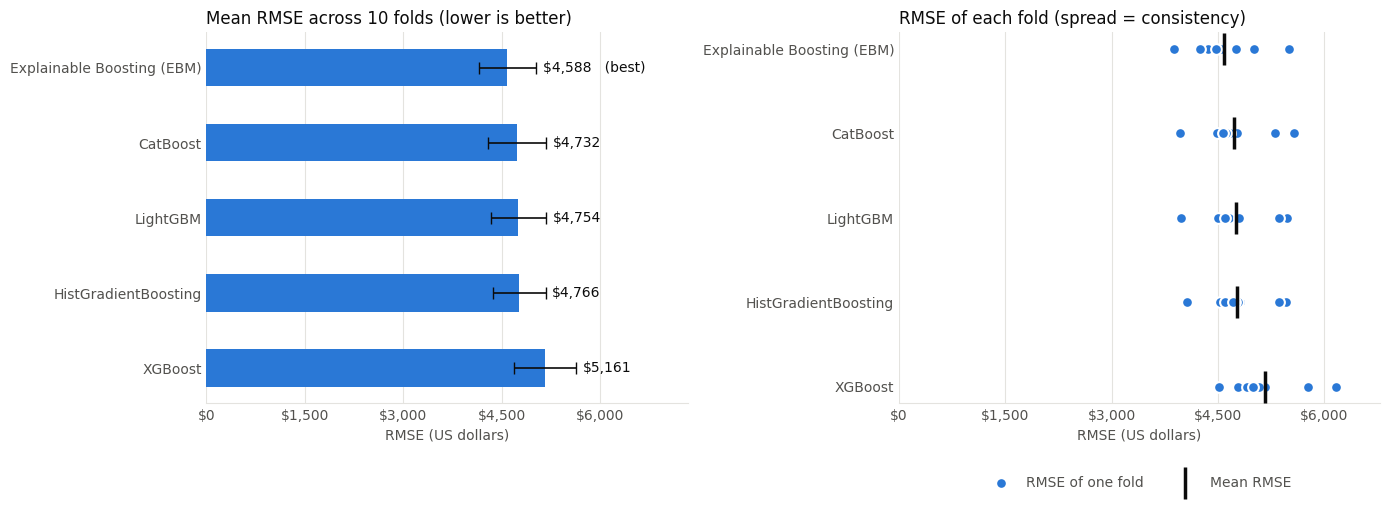

In [ ]:
# Chart colours: one blue for the data, dark/grey text, light grid
BAR_COLOR = "#2a78d6"
TEXT_COLOR = "#0b0b0b"
MUTED_TEXT = "#52514e"
GRID_COLOR = "#e4e3df"
dollars = FuncFormatter(lambda value, _: f"${value:,.0f}")

def style_axis(ax):
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID_COLOR)
    ax.tick_params(colors=MUTED_TEXT, length=0)
    ax.xaxis.set_major_formatter(dollars)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.grid(axis="x", color=GRID_COLOR, linewidth=0.8)
    ax.set_axisbelow(True)

order = summary.index.tolist()            # best algorithm first
positions = np.arange(len(order))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

# ---- Chart 1: mean RMSE with +/- 1 std ----
means = summary["Mean RMSE ($)"]
stds = summary["Std RMSE ($)"]
ax1.barh(positions, means, height=0.5, color=BAR_COLOR,
         xerr=stds, error_kw=dict(ecolor=TEXT_COLOR, elinewidth=1.2, capsize=4))
for i, name in enumerate(order):
    label = f"${means[name]:,.0f}" + ("   (best)" if i == 0 else "")
    ax1.text(means[name] + stds[name] + means.max() * 0.02, i, label,
             va="center", color=TEXT_COLOR, fontsize=10)
ax1.set_yticks(positions, order, color=TEXT_COLOR)
ax1.invert_yaxis()
ax1.set_xlim(0, (means + stds).max() * 1.3)
style_axis(ax1)
ax1.set_title("Mean RMSE across 10 folds (lower is better)", loc="left", color=TEXT_COLOR, fontsize=12)
ax1.set_xlabel("RMSE (US dollars)", color=MUTED_TEXT)

# ---- Chart 2: RMSE of every fold ----
for i, name in enumerate(order):
    ax2.scatter(per_fold_table[name], np.full(K, i), s=60, color=BAR_COLOR,
                edgecolor="white", linewidth=1.5, zorder=3,
                label="RMSE of one fold" if i == 0 else None)
    ax2.scatter(means[name], i, marker="|", s=500, color=TEXT_COLOR, linewidth=2.5, zorder=4,
                label="Mean RMSE" if i == 0 else None)
ax2.set_yticks(positions, order, color=TEXT_COLOR)
ax2.invert_yaxis()
ax2.set_xlim(0, per_fold_table.values.max() * 1.1)
style_axis(ax2)
ax2.set_title("RMSE of each fold (spread = consistency)", loc="left", color=TEXT_COLOR, fontsize=12)
ax2.set_xlabel("RMSE (US dollars)", color=MUTED_TEXT)
ax2.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, labelcolor=MUTED_TEXT)

plt.tight_layout()
plt.show()

## Step 9.4: Observations

> The numbers below come from our run. If your library versions are different, your numbers may differ slightly, but the overall pattern should be the same.

1. **Explainable Boosting (EBM) has the lowest mean RMSE (≈ $4,590)**, followed by **CatBoost (≈ $4,730)**, **LightGBM (≈ $4,750)** and **HistGradientBoosting (≈ $4,770)**. The gap between EBM and the runner-up (≈ $145) is small compared with the standard deviation (≈ $400 – $500), so in practice the top four algorithms are **close to tied**.
2. **XGBoost is the weakest of the five (≈ $5,160)**, about $400 – $570 behind the others. Even so, all five algorithms fall in a **narrow range (≈ $4,600 – $5,200)**. Medical charges depend mostly on a few strong features (smoking status, age and BMI), which every modern boosting method captures, so the choice of algorithm matters much less than the choice of features.
3. **The folds matter more than the algorithms.** Across the 10 folds, individual RMSE values range from ≈ $3,900 to ≈ $6,200 for every algorithm, and algorithms tend to do well or badly on the *same* folds. A fold that happens to contain several very high-cost patients (usually smokers with high BMI) raises every algorithm's error at once.
4. **This shows the effect of RMSE squaring large errors** (Step 3.1): the best mean RMSE (≈ $4,590) is about 35% of the average charges (≈ $13,280), but for a typical non-smoker the error is much smaller than that.
5. **Accuracy vs. speed:** [slowest algorithm] takes ≈ [T1] s in total, while [fastest algorithm] takes ≈ [T2] s with a similar RMSE. In a real project this trade-off matters.
6. **10 folds give a more reliable comparison** than the 3 folds on 100 records: each algorithm is tested 10 times on about 134 records, instead of 3 times on about 33 records.

# Step 10: Train the Final Model
## Step 10.1: Select the Best Algorithm

**Cross validation is used to *choose* an algorithm, not to produce the final model.** The 10 models built during cross validation were only used to measure performance and are now thrown away.

We select the algorithm with the **lowest mean RMSE** from the summary table.

In [ ]:
best_algorithm_name = summary.index[0]
best_mean_rmse = summary.loc[best_algorithm_name, "Mean RMSE ($)"]
best_std_rmse = summary.loc[best_algorithm_name, "Std RMSE ($)"]

print(f"Best algorithm : {best_algorithm_name}")
print(f"Expected RMSE  : ${best_mean_rmse:,.2f} (+/- ${best_std_rmse:,.2f})")

Best algorithm : Explainable Boosting (EBM)
Expected RMSE  : $4,588.35 (+/- $438.64)


## Step 10.2: Train the Best Algorithm on All the Data

Now that we know which algorithm works best, we train it on **all records**. There is no separate test set here, because the cross-validation RMSE from Step 9 is already our estimate of how well this model will perform on new, unseen patients.

In [ ]:
final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", algorithms[best_algorithm_name]),
])

final_model.fit(X, y)

print(f"Final {best_algorithm_name} model trained on {len(X):,} records.")


Final Explainable Boosting (EBM) model trained on 1,337 records.


## Step 10.3: Save the Trained Model

The saved file contains the **whole pipeline** (imputer, scaler, one-hot encoder **and** the algorithm), so it can predict directly from raw car specifications.

To download the model file to your computer in Colab, set `DOWNLOAD_MODEL = True` and run the cell again, or use the **Files** panel (folder icon) on the left.

In [ ]:
MODEL_FILE = "insurance_cost_model_full_dataset.pkl"
DOWNLOAD_MODEL = False

with open(MODEL_FILE, "wb") as f:
    pickle.dump(final_model, f)

print(f"Trained model saved as '{MODEL_FILE}'")

if IN_COLAB and DOWNLOAD_MODEL:
    files.download(MODEL_FILE)

Trained model saved as 'insurance_cost_model_full_dataset.pkl'


# Step 11: Execute the Application Phase
## Step 11.1: Take Input from User

By default the notebook uses the example person below, so that **Run all** works without stopping. To type in your own details, set `USE_INTERACTIVE_INPUT = True` and run the cell again.


In [ ]:
USE_INTERACTIVE_INPUT = False

example_person = {
    "age": 19,
    "bmi": 27.9,
    "children": 0,
    "sex": "female",
    "smoker": "yes",
    "region": "southwest",
}

def get_person_input():
    print("Enter Person Details (ranges seen in the data are shown):")
    print(f"  Age      : {X['age'].min()} - {X['age'].max()}")
    print(f"  BMI      : {X['bmi'].min():.2f} - {X['bmi'].max():.2f}")
    print(f"  Children : {X['children'].min()} - {X['children'].max()}")

    person = {
        "age": int(input("Age: ")),
        "bmi": float(input("BMI: ")),
        "children": int(input("Number of children: ")),
    }
    print("\nAvailable sex values:", sorted(X["sex"].unique()))
    person["sex"] = input("Sex: ").strip().lower()
    print("\nAvailable smoker values:", sorted(X["smoker"].unique()))
    person["smoker"] = input("Smoker: ").strip().lower()
    print("\nAvailable regions:", sorted(X["region"].unique()))
    person["region"] = input("Region: ").strip().lower()
    return person

user_input = get_person_input() if USE_INTERACTIVE_INPUT else example_person

print("Person details:")
for feature, value in user_input.items():
    print(f"  {feature:<10}: {value}")

Person details:
  age       : 19
  bmi       : 27.9
  children  : 0
  sex       : female
  smoker    : yes
  region    : southwest


## Step 11.2: Convert User Input into Feature Vector

The feature vector must have **exactly the same columns, in the same order,** as the training data. There is no need to encode it manually: the saved pipeline scales and one-hot encodes it automatically.

In [ ]:
feature_vector = pd.DataFrame([user_input])[numeric_features + categorical_features]
feature_vector

,age,bmi,children,sex,smoker,region
0,19,27.90,0,female,yes,southwest


## Step 11.3: Load the Saved Model

In [ ]:
with open(MODEL_FILE, "rb") as f:
    loaded_model = pickle.load(f)

print(f"Model loaded from '{MODEL_FILE}': {loaded_model.named_steps['regressor'].__class__.__name__}")

Model loaded from 'insurance_cost_model_full_dataset.pkl': ExplainableBoostingRegressor


## Step 11.4: Model Prediction

Apply the model to the feature vector of the unseen person and return the predicted insurance charges to the user.

In [ ]:
predicted_price = loaded_model.predict(feature_vector)[0]

print(f"Predicted Price (MSRP): ${predicted_price:,.2f}")
print(f"Typical error (cross-validation RMSE of {best_algorithm_name}): about ${best_mean_rmse:,.0f}")

Predicted Price (MSRP): $20,081.60
Typical error (cross-validation RMSE of Explainable Boosting (EBM)): about $4,588


# Step 12: Execute the Feedback Phase

After deployment, feedback from users and domain experts (e.g. insurance underwriters and healthcare analysts) is used to improve the model. Potential improvements for this system:

1. **Add more features**: this dataset has only 6 inputs. Details such as medical history, pre-existing conditions, exercise habits, alcohol use or family history of illness are not included, yet they would likely explain a lot of the remaining error.
2. **Tune hyper-parameters**: e.g. the learning rate, number of trees and tree depth of XGBoost, LightGBM, CatBoost and HistGradientBoosting. Use cross validation (`GridSearchCV` or `RandomizedSearchCV`) to choose them.
3. **Handle very high-cost patients**: train a separate model for smokers, who have much higher charges, or report an error measure that is less sensitive to outliers (e.g. MAE) alongside RMSE.
4. **Collect more data**: the dataset has only 1,337 records, so each test fold has about 134 records. A larger, more recent dataset would give a more reliable comparison between the algorithms and make the small RMSE gaps between them easier to interpret.
5. **Check for fairness**: features such as *sex*, *age* and *region* can affect real insurance pricing, so the model's predictions should be reviewed for bias and compared with the pricing rules that apply to your use case before anyone relies on them.

# Conclusion

In this notebook we compared **5 regression algorithms** on the **full medical insurance dataset (1,337 unique records)** using **10-fold cross validation** and **RMSE**.

- **Explainable Boosting Machine (EBM)** achieved the lowest mean RMSE (≈ $4,590), with **CatBoost (≈ $4,730)**, **LightGBM (≈ $4,750)** and **HistGradientBoosting (≈ $4,770)** very close behind. The gaps between these four are small compared with the fold-to-fold variation (standard deviation ≈ $400 – $500), so they are **practically tied**. EBM was trained on all the records, saved, and used to predict the charges of a new person.
- **XGBoost performed worst** (≈ $5,160), although only about $570 behind the best, so all five algorithms fall in a **narrow range**. Medical charges depend mostly on a few strong features (especially smoking status, together with age and BMI), which every modern boosting method captures.
- The best mean RMSE is about **35% of the average charges (≈ $13,280)**. The RMSE is strongly affected by a few very high-cost patients, usually smokers, so for typical non-smokers the errors are much smaller.
- With only about 134 test records per fold, we should be careful about declaring a single winner. The differences among the top four algorithms are within the noise of the experiment.

### Comparison With 100 Instances (Companion Notebook)

| Algorithm | Mean RMSE – 100 records, 3-fold | Mean RMSE – full data, 10-fold |
|---|---|---|
| Explainable Boosting (EBM) | [fill in] | **$4,588** (rank 1) |
| CatBoost | [fill in] | $4,732 (rank 2) |
| LightGBM | [fill in] | $4,754 (rank 3) |
| HistGradientBoosting | [fill in] | $4,766 (rank 4) |
| XGBoost | [fill in] | $5,161 (rank 5) |

[Write one or two sentences here from the filled table, such as whether every algorithm's error dropped with the full data and whether the ranking changed.] The general lesson holds: **more data gives better models and more trustworthy comparisons.**

##Downloading Requirements and Trained Model file:

The below cell writes requirements.txt with the exact library versions the model was trained with (mismatched versions are the most common reason a pickle fails to load) and downloads both files.

In [ ]:
import importlib.metadata as md

best_class = loaded_model.named_steps["regressor"].__class__.__name__

needed = ["scikit-learn", "pandas", "numpy"]
if "Explainable" in best_class: needed.append("interpret")
if "CatBoost" in best_class:    needed.append("catboost")
if "LGBM" in best_class:        needed.append("lightgbm")
if "XGB" in best_class:         needed.append("xgboost")

with open("requirements.txt", "w") as f:
    f.write("streamlit\n")
    for p in needed:
        f.write(f"{p}=={md.version(p)}\n")

print(open("requirements.txt").read())
files.download("requirements.txt")
files.download(MODEL_FILE)

streamlit
scikit-learn==1.6.1
pandas==2.2.3
numpy==2.1.3
interpret==0.7.8



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>